# Sales Data Cleaning Using Python and Pandas

## Project Overview
This project demonstrates how Python and Pandas can be used to clean and standardise a messy sales dataset containing duplicate records, missing values, inconsistent text formatting and invalid dates.

## Project Objectives
- Identify and remove exact duplicate records.
- Standardise customer names, email addresses and product names.
- Convert price and quantity columns into numeric formats.
- Standardise mixed date formats and identify invalid dates.
- Preserve unresolved missing values for verification.
- Export cleaned data, a quality report and an exception report.

## Dataset
- Original records: 38
- Cleaned records: 35
- Exact duplicates removed: 3
- Remaining missing cells: 4

The dataset is synthetic and is used for portfolio demonstration purposes.

In [1]:
import pandas as pd
from pathlib import Path

file_path = Path("messy_sales_data.csv")
df = pd.read_csv(file_path, dtype=str, keep_default_na=False)
print("Original rows:", len(df))
display(df.head(10))

Original rows: 38


,Order ID,Customer Name,Email,Product,Unit Price,Quantity,Order Date,Status
0,ORD-001,John Smith,john.smith@example.com,Laptop,950,2,2026-09-02,Completed
1,ORD-002,Jane Adams,jane.adams@example.com,Mouse,25,3,2026-09-03,Completed
2,ORD-003,sara khan,sara.khan@example.com,Keyboard,65,1,2026-09-04,Completed
3,ORD-004,Mike Lee,mike.lee@example.com,Monitor,220,2,2026-09-05,Completed
4,ORD-005,David Ali,DAVID.ALI@EXAMPLE.COM,Desk,190,3,2026-09-06,Completed
5,ORD-006,Anna Brown,anna.brown@example.com,Chair,120,1,2026-09-07,Completed
6,ORD-007,Chris Green,chris.green@example.com,Webcam,75,2,2026-09-08,Completed
7,ORD-008,John Smith,john.smith@example.com,monitor,950,3,2026-09-09,Completed
8,ORD-009,Jane Adams,jane.adams@example.com,Mouse,25,1,2026-09-10,Completed
9,ORD-010,Sara Khan,sara.khan@example.com,Keyboard,,2,2026-09-11,Completed


In [2]:

df.shape


(38, 8)

In [3]:

df.columns


Index(['Order ID', 'Customer Name', 'Email', 'Product', 'Unit Price',
       'Quantity', 'Order Date', 'Status'],
      dtype='object')

In [4]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38 entries, 0 to 37
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Order ID       38 non-null     object
 1   Customer Name  38 non-null     object
 2   Email          38 non-null     object
 3   Product        38 non-null     object
 4   Unit Price     38 non-null     object
 5   Quantity       38 non-null     object
 6   Order Date     38 non-null     object
 7   Status         38 non-null     object
dtypes: object(8)
memory usage: 2.5+ KB


In [5]:

df.isnull().sum()


Order ID         0
Customer Name    0
Email            0
Product          0
Unit Price       0
Quantity         0
Order Date       0
Status           0
dtype: int64

In [6]:

for col in df.columns:
    print(f"\nColumn: {col}")
    print(df[col].unique())



Column: Order ID
['ORD-001' 'ORD-002' 'ORD-003' 'ORD-004' 'ORD-005' 'ORD-006' 'ORD-007'
 'ORD-008' 'ORD-009' 'ORD-010' 'ORD-011' 'ORD-012' 'ORD-013' 'ORD-014'
 'ORD-015' 'ORD-016' 'ORD-017' 'ORD-018' 'ORD-019' 'ORD-020' 'ORD-021'
 'ORD-022' 'ORD-023' 'ORD-024' 'ORD-025' 'ORD-026' 'ORD-027' 'ORD-028'
 'ORD-029' 'ORD-030' 'ORD-031' 'ORD-032' 'ORD-033' 'ORD-034' 'ORD-035']

Column: Customer Name
['John Smith' 'Jane Adams' ' sara khan ' 'Mike Lee' 'David Ali'
 'Anna Brown' 'Chris Green' 'Sara Khan' 'ANNA BROWN']

Column: Email
['john.smith@example.com' 'jane.adams@example.com' 'sara.khan@example.com'
 'mike.lee@example.com' ' DAVID.ALI@EXAMPLE.COM ' 'anna.brown@example.com'
 'chris.green@example.com' 'david.ali@example.com']

Column: Product
['Laptop' 'Mouse' 'Keyboard' 'Monitor' 'Desk' 'Chair' 'Webcam' ' monitor '
 'keyBOARD']

Column: Unit Price
['950' '25' '65' '220' '190' '120' '75' '' 'N/A']

Column: Quantity
['2' '3' '1' '' 'two']

Column: Order Date
['2026-09-02' '2026-09-03' '2026

In [7]:

for col in df.columns:
    empty_count = (df[col].str.strip() == "").sum()
    print(f"{col}: {empty_count} empty values")


Order ID: 0 empty values
Customer Name: 0 empty values
Email: 0 empty values
Product: 0 empty values
Unit Price: 1 empty values
Quantity: 1 empty values
Order Date: 0 empty values
Status: 0 empty values


In [8]:

df[
    (df["Unit Price"].str.strip() == "") |
    (df["Unit Price"].str.strip() == "N/A") |
    (df["Quantity"].str.strip() == "")
]


,Order ID,Customer Name,Email,Product,Unit Price,Quantity,Order Date,Status
9,ORD-010,Sara Khan,sara.khan@example.com,Keyboard,,2,2026-09-11,Completed
11,ORD-012,David Ali,david.ali@example.com,Desk,190,,2026-09-13,Completed
18,ORD-019,David Ali,david.ali@example.com,Desk,N/A,2,2026-09-20,Completed


In [9]:

df_clean = df.copy()


In [10]:

print("Original dataset:", df.shape)
print("Working copy:", df_clean.shape)


Original dataset: (38, 8)
Working copy: (38, 8)


In [11]:

import numpy as np


In [12]:

df_clean = df_clean.replace(
    ["", " ", "N/A"],
    np.nan
)


In [13]:

df_clean.isnull().sum()


Order ID         0
Customer Name    0
Email            0
Product          0
Unit Price       2
Quantity         1
Order Date       0
Status           0
dtype: int64

In [14]:
df_clean[df_clean.isnull().any(axis=1)]

,Order ID,Customer Name,Email,Product,Unit Price,Quantity,Order Date,Status
9,ORD-010,Sara Khan,sara.khan@example.com,Keyboard,NaN,2,2026-09-11,Completed
11,ORD-012,David Ali,david.ali@example.com,Desk,190,NaN,2026-09-13,Completed
18,ORD-019,David Ali,david.ali@example.com,Desk,NaN,2,2026-09-20,Completed


In [15]:

df_clean[df_clean["Product"] == "Keyboard"]


,Order ID,Customer Name,Email,Product,Unit Price,Quantity,Order Date,Status
2,ORD-003,sara khan,sara.khan@example.com,Keyboard,65,1,2026-09-04,Completed
9,ORD-010,Sara Khan,sara.khan@example.com,Keyboard,NaN,2,2026-09-11,Completed
16,ORD-017,Sara Khan,sara.khan@example.com,Keyboard,65,3,2026-09-18,Completed
23,ORD-024,Sara Khan,sara.khan@example.com,Keyboard,65,1,2026-09-25,Completed


In [16]:

df_clean[
    df_clean["Product"].str.strip().str.lower() == "keyboard"
]


,Order ID,Customer Name,Email,Product,Unit Price,Quantity,Order Date,Status
2,ORD-003,sara khan,sara.khan@example.com,Keyboard,65,1,2026-09-04,Completed
9,ORD-010,Sara Khan,sara.khan@example.com,Keyboard,NaN,2,2026-09-11,Completed
16,ORD-017,Sara Khan,sara.khan@example.com,Keyboard,65,3,2026-09-18,Completed
23,ORD-024,Sara Khan,sara.khan@example.com,Keyboard,65,1,2026-09-25,Completed
30,ORD-031,Sara Khan,sara.khan@example.com,keyBOARD,65,2,2026-09-05,Completed


In [17]:

keyboard = df_clean[
    df_clean["Product"].str.strip().str.lower() == "keyboard"
]

keyboard["Unit Price"].value_counts(dropna=False)


Unit Price
65     4
NaN    1
Name: count, dtype: int64

In [18]:

desk = df_clean[
    df_clean["Product"].str.strip().str.lower() == "desk"
]

desk



,Order ID,Customer Name,Email,Product,Unit Price,Quantity,Order Date,Status
4,ORD-005,David Ali,DAVID.ALI@EXAMPLE.COM,Desk,190,3,2026-09-06,Completed
11,ORD-012,David Ali,david.ali@example.com,Desk,190,NaN,2026-09-13,Completed
18,ORD-019,David Ali,david.ali@example.com,Desk,NaN,2,2026-09-20,Completed
25,ORD-026,David Ali,david.ali@example.com,Desk,190,3,2026-09-27,Completed
32,ORD-033,David Ali,david.ali@example.com,Desk,190,1,not a date,Completed
36,ORD-005,David Ali,DAVID.ALI@EXAMPLE.COM,Desk,190,3,2026-09-06,Completed


In [19]:

df_clean["Unit Price"] = pd.to_numeric(
    df_clean["Unit Price"],
    errors="coerce"
)


In [20]:

df_clean["Unit Price"].dtype


dtype('float64')

In [21]:

df_clean["Unit Price"].isnull().sum()


np.int64(2)

In [22]:

df_clean[df_clean["Quantity"] == "two"]


,Order ID,Customer Name,Email,Product,Unit Price,Quantity,Order Date,Status
27,ORD-028,Chris Green,chris.green@example.com,Webcam,75.0,two,2026-09-02,Completed


In [23]:

df_clean["Quantity"] = df_clean["Quantity"].replace(
    "two", "2"
)


In [24]:

print("Data type:", df_clean["Quantity"].dtype)

print("Missing values:", df_clean["Quantity"].isnull().sum())

print(
    df_clean.loc[
        df_clean["Order ID"] == "ORD-028",
        ["Order ID", "Product", "Quantity"]
    ]
)


Data type: object
Missing values: 1
   Order ID Product Quantity
27  ORD-028  Webcam        2


In [25]:

df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"],
    errors="coerce"
)

print(df_clean["Quantity"].dtype)


float64


In [26]:

print(df_clean["Quantity"].isnull().sum())

print(
    df_clean.loc[
        df_clean["Order ID"] == "ORD-028",
        ["Order ID", "Product", "Quantity"]
    ]
)



1
   Order ID Product  Quantity
27  ORD-028  Webcam       2.0


In [27]:
df_clean["Quantity"].sum()

np.float64(78.0)

In [28]:

print("Data type:", df_clean["Quantity"].dtype)

print("Missing values:", df_clean["Quantity"].isna().sum())

print("Total quantity:", df_clean["Quantity"].sum())


Data type: float64
Missing values: 1
Total quantity: 78.0


In [29]:

df_clean.duplicated().sum()


np.int64(3)

In [30]:

df_clean[df_clean.duplicated(keep=False)]


,Order ID,Customer Name,Email,Product,Unit Price,Quantity,Order Date,Status
0,ORD-001,John Smith,john.smith@example.com,Laptop,950.0,2.0,2026-09-02,Completed
4,ORD-005,David Ali,DAVID.ALI@EXAMPLE.COM,Desk,190.0,3.0,2026-09-06,Completed
10,ORD-011,Mike Lee,mike.lee@example.com,Monitor,220.0,3.0,2026-09-12,Completed
35,ORD-001,John Smith,john.smith@example.com,Laptop,950.0,2.0,2026-09-02,Completed
36,ORD-005,David Ali,DAVID.ALI@EXAMPLE.COM,Desk,190.0,3.0,2026-09-06,Completed
37,ORD-011,Mike Lee,mike.lee@example.com,Monitor,220.0,3.0,2026-09-12,Completed


In [31]:

df_clean = df_clean.drop_duplicates(
    keep="first"
).copy()


In [32]:

print("Original rows:", len(df))

print("Cleaned rows:", len(df_clean))

print("Remaining duplicates:",
      df_clean.duplicated().sum())


Original rows: 38
Cleaned rows: 35
Remaining duplicates: 0


In [33]:

total_quantity = df_clean["Quantity"].sum()

print("Total quantity after removing duplicates:", total_quantity)


Total quantity after removing duplicates: 70.0


In [34]:

df_clean["Order ID"].duplicated().sum()


np.int64(0)

In [35]:

df_clean["Customer Name"] = (
    df_clean["Customer Name"]
    .str.strip()
    .str.title()
)



In [36]:

df_clean["Customer Name"].unique()



array(['John Smith', 'Jane Adams', 'Sara Khan', 'Mike Lee', 'David Ali',
       'Anna Brown', 'Chris Green'], dtype=object)

In [37]:

df_clean["Email"] = (
    df_clean["Email"]
    .str.strip()
    .str.lower()
)


In [38]:

df_clean["Email"].unique()


array(['john.smith@example.com', 'jane.adams@example.com',
       'sara.khan@example.com', 'mike.lee@example.com',
       'david.ali@example.com', 'anna.brown@example.com',
       'chris.green@example.com'], dtype=object)

In [39]:

df_clean["Product"].unique()


array(['Laptop', 'Mouse', 'Keyboard', 'Monitor', 'Desk', 'Chair',
       'Webcam', ' monitor ', 'keyBOARD'], dtype=object)

In [40]:

df_clean["Product"] = (
    df_clean["Product"]
    .str.strip()
    .str.title()
)


df_clean["Product"].unique()


array(['Laptop', 'Mouse', 'Keyboard', 'Monitor', 'Desk', 'Chair',
       'Webcam'], dtype=object)

In [41]:

df_clean["Order Date"].dtype


dtype('O')

In [42]:

df_clean[
    df_clean["Order Date"].isin(
        ["09/15/2026", "2026/09/22", "not a date"]
    )
][["Order ID", "Order Date"]]


,Order ID,Order Date
13,ORD-014,09/15/2026
20,ORD-021,2026/09/22
32,ORD-033,not a date


In [43]:
pd.to_datetime(
    df_clean["Order Date"],
    format="mixed",
    errors="coerce"
)


0    2026-09-02
1    2026-09-03
2    2026-09-04
3    2026-09-05
4    2026-09-06
5    2026-09-07
6    2026-09-08
7    2026-09-09
8    2026-09-10
9    2026-09-11
10   2026-09-12
11   2026-09-13
12   2026-09-14
13   2026-09-15
14   2026-09-16
15   2026-09-17
16   2026-09-18
17   2026-09-19
18   2026-09-20
19   2026-09-21
20   2026-09-22
21   2026-09-23
22   2026-09-24
23   2026-09-25
24   2026-09-26
25   2026-09-27
26   2026-09-01
27   2026-09-02
28   2026-09-03
29   2026-09-04
30   2026-09-05
31   2026-09-06
32          NaT
33   2026-09-08
34   2026-09-09
Name: Order Date, dtype: datetime64[ns]

In [44]:

df_clean[
    df_clean["Order Date"].isna()
][["Order ID", "Customer Name", "Order Date"]]


,Order ID,Customer Name,Order Date


In [45]:

print("Data type:", df_clean["Order Date"].dtype)

print("Missing dates:", df_clean["Order Date"].isna().sum())


Data type: object
Missing dates: 0


In [46]:
df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"],
    format="mixed",
    errors="coerce"
)

In [47]:
pd.to_datetime(
    df_clean["Order Date"],
    format="mixed",
    errors="coerce"
)

0    2026-09-02
1    2026-09-03
2    2026-09-04
3    2026-09-05
4    2026-09-06
5    2026-09-07
6    2026-09-08
7    2026-09-09
8    2026-09-10
9    2026-09-11
10   2026-09-12
11   2026-09-13
12   2026-09-14
13   2026-09-15
14   2026-09-16
15   2026-09-17
16   2026-09-18
17   2026-09-19
18   2026-09-20
19   2026-09-21
20   2026-09-22
21   2026-09-23
22   2026-09-24
23   2026-09-25
24   2026-09-26
25   2026-09-27
26   2026-09-01
27   2026-09-02
28   2026-09-03
29   2026-09-04
30   2026-09-05
31   2026-09-06
32          NaT
33   2026-09-08
34   2026-09-09
Name: Order Date, dtype: datetime64[ns]

In [48]:

df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"],
    format="mixed",
    errors="coerce"
)

print("Data type:", df_clean["Order Date"].dtype)
print("Missing dates:", df_clean["Order Date"].isna().sum())


Data type: datetime64[ns]
Missing dates: 1


In [49]:

df_clean.loc[
    df_clean["Order Date"].isna(),
    ["Order ID", "Customer Name", "Product", "Order Date"]
]


,Order ID,Customer Name,Product,Order Date
32,ORD-033,David Ali,Desk,NaT


In [50]:

df_clean["Status"] = (
    df_clean["Status"]
    .str.strip()
    .str.title()
)


In [51]:

df_clean["Status"].value_counts(dropna=False)


Status
Completed    35
Name: count, dtype: int64

In [52]:

df_clean.isnull().sum()


Order ID         0
Customer Name    0
Email            0
Product          0
Unit Price       2
Quantity         1
Order Date       1
Status           0
dtype: int64

In [53]:

df_clean.info()


<class 'pandas.core.frame.DataFrame'>
Index: 35 entries, 0 to 34
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order ID       35 non-null     object        
 1   Customer Name  35 non-null     object        
 2   Email          35 non-null     object        
 3   Product        35 non-null     object        
 4   Unit Price     33 non-null     float64       
 5   Quantity       34 non-null     float64       
 6   Order Date     34 non-null     datetime64[ns]
 7   Status         35 non-null     object        
dtypes: datetime64[ns](1), float64(2), object(5)
memory usage: 2.5+ KB


In [54]:

quality_report = pd.DataFrame({
    "Metric": [
        "Original Records",
        "Cleaned Records",
        "Duplicates Removed",
        "Remaining Exact Duplicates",
        "Missing Unit Prices",
        "Missing Quantities",
        "Missing Order Dates"
    ],
    "Value": [
        len(df),
        len(df_clean),
        len(df) - len(df_clean),
        df_clean.duplicated().sum(),
        df_clean["Unit Price"].isna().sum(),
        df_clean["Quantity"].isna().sum(),
        df_clean["Order Date"].isna().sum()
    ]
})

quality_report


,Metric,Value
0,Original Records,38
1,Cleaned Records,35
2,Duplicates Removed,3
3,Remaining Exact Duplicates,0
4,Missing Unit Prices,2
5,Missing Quantities,1
6,Missing Order Dates,1


In [55]:

exception_report = df_clean[
    df_clean[
        ["Unit Price", "Quantity", "Order Date"]
    ].isna().any(axis=1)
].copy()

exception_report[
    ["Order ID", "Customer Name", "Product",
     "Unit Price", "Quantity", "Order Date"]
]


,Order ID,Customer Name,Product,Unit Price,Quantity,Order Date
9,ORD-010,Sara Khan,Keyboard,NaN,2.0,2026-09-11
11,ORD-012,David Ali,Desk,190.0,NaN,2026-09-13
18,ORD-019,David Ali,Desk,NaN,2.0,2026-09-20
32,ORD-033,David Ali,Desk,190.0,1.0,NaT


In [56]:

df_clean.to_csv(
    "cleaned_sales_data.csv",
    index=False
)


In [57]:

import os

print(os.path.exists("cleaned_sales_data.csv"))


True


In [58]:

quality_report.to_csv(
    "data_quality_report.csv",
    index=False
)


In [59]:

import os

print(os.path.exists("data_quality_report.csv"))


True


In [60]:

exception_report.to_csv(
    "exception_report.csv",
    index=False
)


In [61]:

import os

print(os.path.exists("exception_report.csv"))


True


In [62]:

print("Exception records:", len(exception_report))


Exception records: 4


In [63]:

comparison = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Exact Duplicate Rows",
        "Unique Order IDs",
        "Number of Columns"
    ],
    "Before Cleaning": [
        len(df),
        df.duplicated().sum(),
        df["Order ID"].nunique(),
        df.shape[1]
    ],
    "After Cleaning": [
        len(df_clean),
        df_clean.duplicated().sum(),
        df_clean["Order ID"].nunique(),
        df_clean.shape[1]
    ]
})

comparison


,Metric,Before Cleaning,After Cleaning
0,Total Records,38,35
1,Exact Duplicate Rows,3,0
2,Unique Order IDs,35,35
3,Number of Columns,8,8


In [64]:

import matplotlib.pyplot as plt


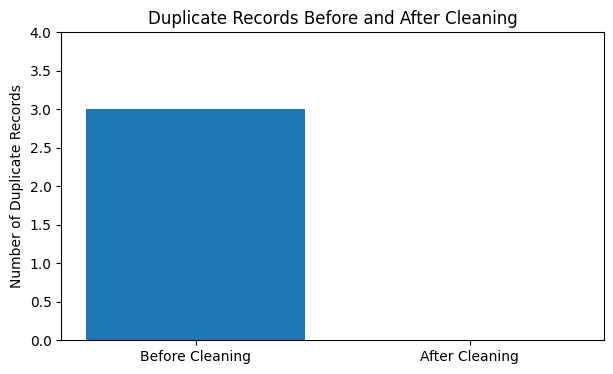

In [65]:

before = df.duplicated().sum()
after = df_clean.duplicated().sum()

plt.figure(figsize=(7, 4))

plt.bar(
    ["Before Cleaning", "After Cleaning"],
    [before, after]
)

plt.title("Duplicate Records Before and After Cleaning")
plt.ylabel("Number of Duplicate Records")
plt.ylim(0, 4)

plt.show()


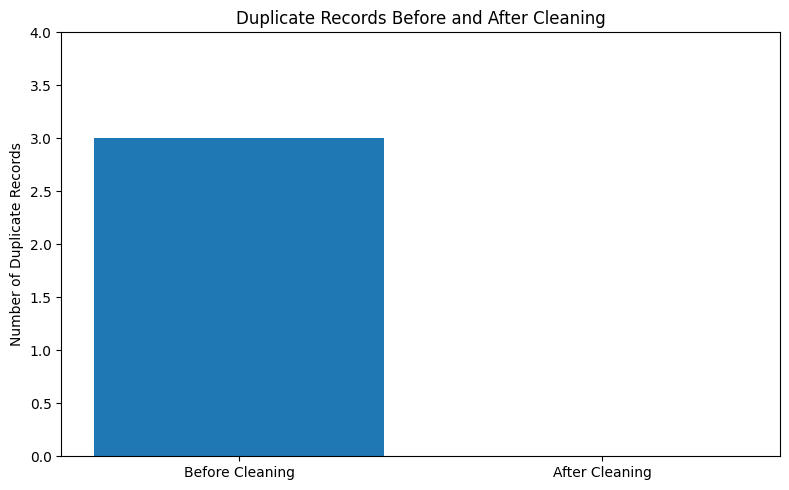

In [66]:

plt.figure(figsize=(8, 5))

plt.bar(
    ["Before Cleaning", "After Cleaning"],
    [df.duplicated().sum(), df_clean.duplicated().sum()]
)

plt.title("Duplicate Records Before and After Cleaning")
plt.ylabel("Number of Duplicate Records")
plt.ylim(0, 4)

plt.tight_layout()

plt.savefig(
    "duplicate_cleaning_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [67]:

import os

print(os.path.exists("duplicate_cleaning_comparison.png"))


True


In [68]:

before_after = pd.DataFrame({
    "Cleaning Task": [
        "Customer Name",
        "Customer Name",
        "Email",
        "Product Name",
        "Product Name",
        "Quantity",
        "Invalid Date"
    ],
    "Before Cleaning": [
        " sara khan ",
        "ANNA BROWN",
        " DAVID.ALI@EXAMPLE.COM ",
        " monitor ",
        "keyBOARD",
        "two",
        "not a date"
    ],
    "After Cleaning": [
        "Sara Khan",
        "Anna Brown",
        "david.ali@example.com",
        "Monitor",
        "Keyboard",
        "2",
        "NaT (Flagged for Review)"
    ]
})

before_after



,Cleaning Task,Before Cleaning,After Cleaning
0,Customer Name,sara khan,Sara Khan
1,Customer Name,ANNA BROWN,Anna Brown
2,Email,DAVID.ALI@EXAMPLE.COM,david.ali@example.com
3,Product Name,monitor,Monitor
4,Product Name,keyBOARD,Keyboard
5,Quantity,two,2
6,Invalid Date,not a date,NaT (Flagged for Review)


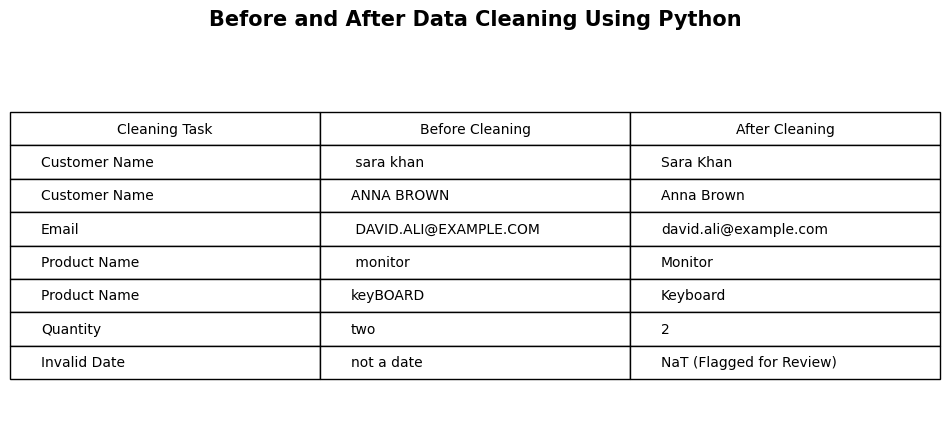

In [69]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))
ax.axis("off")

table = ax.table(
    cellText=before_after.values,
    colLabels=before_after.columns,
    cellLoc="left",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2)

plt.title(
    "Before and After Data Cleaning Using Python",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.savefig(
    "before_after_data_cleaning.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



In [70]:

import os

print(os.path.exists("before_after_data_cleaning.png"))



True


In [71]:

import os

folder_name = "Fiverr_Data_Cleaning_Portfolio"

os.makedirs(folder_name, exist_ok=True)

print("Project folder created!")


Project folder created!


In [72]:

print(os.path.exists(folder_name))


True


In [73]:

print("Original records:", len(df))
print("Cleaned records:", len(df_clean))
print("Remaining duplicates:", df_clean.duplicated().sum())
print("Unique Order IDs:", df_clean["Order ID"].nunique())
print("Missing values:", df_clean.isna().sum().sum())


Original records: 38
Cleaned records: 35
Remaining duplicates: 0
Unique Order IDs: 35
Missing values: 4


In [74]:

import os

print("Notebook working directory:")
print(os.getcwd())



Notebook working directory:
C:\Users\Hina Iqbal\Desktop\Fiverr\Fiverr_Data_Cleaning_Portfolio
